<a href="https://colab.research.google.com/github/Raditya-Z/MachineLearning_244107020144/blob/main/JS-11/JS_11_Praktikum2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 💻 Praktikum 2

# Langkah 1 - Ilustrasi Data Non-Linier

### Langkah 1a - Import Library

In [7]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

### Langkah 1b - Buat Kembali Fungsi Plotting

In [8]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### Langkah 1c - Buat Data Dummy Non-Linier

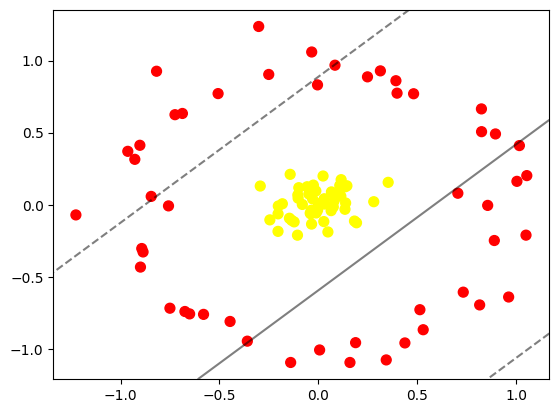

In [9]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

Karena proyeksi radial tidak cukup menggunakan model 2D, maka plot visualisasi diubah menjadi model 3D.

In [10]:
r = np.exp(-(X ** 2).sum(1))

In [11]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-0.10361718,  0.06790336],
       [-0.02930038,  0.04125124],
       [-0.08104548,  0.00232707],
       [-0.12237749, -0.11858987],
       [ 0.07549488, -0.01509724],
       [-0.14616583, -0.09338559],
       [ 0.14443181,  0.13169743],
       [ 1.05397903,  0.20225443],
       [-0.90227369,  0.41250241],
       [-0.03548567, -0.0379199 ],
       [-0.65073467, -0.75664795],
       [-0.10224695,  0.04589275],
       [-0.03794767, -0.0626005 ],
       [-0.44622489, -0.80906533],
       [ 0.06735553,  0.0835928 ],
       [-0.00261567, -0.01636566],
       [ 1.00402538,  0.16251086],
       [ 0.08413105,  0.96781377],
       [ 0.88973504, -0.24777979],
       [-0.00414616,  0.83128206],
       [ 0.73266801, -0.6059179 ],
       [-1.22574954, -0.07030263],
       [-0.58036634, -0.7599421 ],
       [ 0.0661272 ,  0.0893163 ],
       [-0.01081389, -0.05671215],
       [-0.20385868, -0.18431315],
       [-0.04114441, -0.05787892],
       [-0.18191912,  0.00696066],
       [-0.96335162,  0.3705924 ],
       [ 0.53015616, -0.86640055],
       [-0.81793736,  0.92588788],
       [ 0.04838545, -0.18846354],
       [ 0.13603835,  0.12483516],
       [-0.20238551, -0.00850056],
       [-0.25072402,  0.9036604 ],
       [ 0.82460127,  0.66474763],
       [ 0.8156409 , -0.69443925],
       [-0.04783822,  0.07489857],
       [-0.30148497,  1.23627811],
       [-0.75031857, -0.71715782],
       [ 0.19309666, -0.12485593],
       [ 0.02966461,  0.00490539],
       [ 0.9621965 , -0.63957869],
       [ 0.11532468,  0.17410045],
       [ 0.00647037, -1.0066358 ],
       [-0.05675243,  0.12500707],
       [ 0.82525892,  0.50689755],
       [ 0.1598934 , -1.09346337],
       [ 0.11385969,  0.05971323],
       [ 0.01202827,  0.01124654],
       [-0.03422746, -0.13395446],
       [-0.29365554,  0.12989927],
       [ 0.1883947 , -0.95603162],
       [ 0.48162855,  0.76977703],
       [ 0.28018571,  0.02126149],
       [ 0.43766479, -0.95798547],
       [ 0.13801825,  0.01235137],
       [ 0.18276419, -0.11287944],
       [ 0.85617842, -0.00430219],
       [-0.20362732, -0.06294038],
       [ 0.24851848,  0.88699617],
       [-0.24508962, -0.10463867],
       [-0.88615191, -0.32714479],
       [-0.67451789, -0.74002068],
       [ 0.51345484, -0.72750897],
       [ 0.02388112,  0.19950315],
       [ 1.04994054, -0.21060988],
       [ 0.39224118,  0.86019177],
       [-0.8927526 , -0.30331113],
       [ 0.89557092,  0.49112134],
       [ 0.34334903, -1.0757385 ],
       [ 0.06470286, -0.04062968],
       [ 0.02772625, -0.11655919],
       [ 0.02969963,  0.04169067],
       [-0.84501322,  0.05801769],
       [-0.35899723, -0.94567237],
       [ 1.01655713,  0.41048347],
       [-0.50684067,  0.77096448],
       [ 0.31369272,  0.92848517],
       [-0.72473104,  0.62463352],
       [-0.03350651,  1.05935991],
       [ 0.07925429,  0.02544924],
       [ 0.35306534,  0.1555932 ],
       [-0.10543272, -0.21083663],
       [-0.75750913, -0.00772805],
       [-0.00375072, -0.03786671],
       [-0.92781541,  0.31513776],
       [-0.13990283, -1.09342878],
       [ 0.39800156,  0.77391447],
       [ 0.70533671,  0.08005278],
       [-0.89928831, -0.43203236],
       [ 0.13476123, -0.03114569],
       [ 0.10844502,  0.13410842],
       [-0.1423897 ,  0.2110849 ],
       [-0.13484774, -0.10779936],
       [ 0.09916887,  0.07177227],
       [-0.68718353,  0.63312961],
       [-0.0987817 ,  0.11842581],
       [-0.02519465,  0.1363461 ],
       [-0.01264353,  0.0960476 ]]), y=array([1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1,
       0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1]))>

# Langkah 2 - Fitting Model

In [12]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

Plot hasil decision boundaries dari kernel RBF

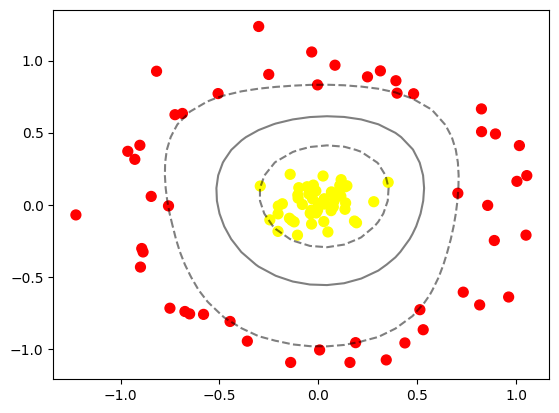

In [13]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')